<a href="https://colab.research.google.com/github/ruqayaahabib/Advanced-AI-Labs/blob/main/Week06-Lab6_Ruqaya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Load the dataset from UCI or from a local bank.csv file.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

df = pd.read_csv("bank.csv", sep=";")

2. Display the first rows, shape, data types, and target distribution.

In [ ]:
display(df.head())
print(df.shape)
print(df.dtypes)
print(df["y"].value_counts())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


(4521, 17)
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object
y
no     4000
yes     521
Name: count, dtype: int64


3. Remove the target column y from the features.

In [ ]:
X = df.drop(columns=["y"])
y = df["y"]

4. Remove the duration column and explain why it can cause leakage.

In [ ]:
X = X.drop(columns=["duration"])

5. Split the data into training and testing sets using stratification.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

6. Build a ColumnTransformer preprocessing pipeline.

In [ ]:
num_cols = X.select_dtypes(include=["number"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

7. Train at least four models:



1.   Logistic Regression baseline.



In [ ]:
lr = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

lr.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='object'))])),
                ('model', LogisticRegression(max_iter=1000))])


2.   Random Forest classifier.



In [ ]:
rf = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='object'))])),
                ('model', RandomForestClassifier(random_state=42))])



3.   Gradient Boosting classifier




In [ ]:
gb = Pipeline([
    ("preprocess", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

gb.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='object'))])),
                ('model', GradientBoostingClassifier(random_state=42))])



4.   One ensemble combination model: soft voting or stacking.




In [ ]:
voting = Pipeline([
    ("preprocess", preprocessor),
    ("model", VotingClassifier(
        estimators=[
            ("lr", LogisticRegression(max_iter=1000)),
            ("rf", RandomForestClassifier(random_state=42)),
            ("gb", GradientBoostingClassifier(random_state=42))
        ],
        voting="soft"
    ))
])

voting.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'balance', 'day', 'campaign', 'pdays', 'previous'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='object'))])),
                ('model',
                 VotingClassifier(estimators=[('lr',
                                               LogisticRegression(max_iter=1000)),
                                              ('rf',
                                               RandomForestClassifier(random_state=42)),
                                              ('gb',
                                               GradientBoostingClassifier(random_state=42))],
                                  voting='soft'))])

8. Evaluate all models using accuracy, precision, recall, F1-score, and ROC-AUC.

In [ ]:
models = {
    "Logistic Regression": lr,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "Soft Voting": voting
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    yes_index = list(model.classes_).index("yes")
    y_prob = model.predict_proba(X_test)[:, yes_index]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="yes"),
        "Recall": recall_score(y_test, y_pred, pos_label="yes"),
        "F1": f1_score(y_test, y_pred, pos_label="yes"),
        "ROC-AUC": roc_auc_score(y_test == "yes", y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.887293,0.533333,0.153846,0.238806,0.737624
1,Random Forest,0.882873,0.466667,0.134615,0.208955,0.708429
2,Gradient Boosting,0.891713,0.571429,0.230769,0.328767,0.771470
3,Soft Voting,0.890608,0.608696,0.134615,0.220472,0.752593


9. Create one confusion matrix for the best model.

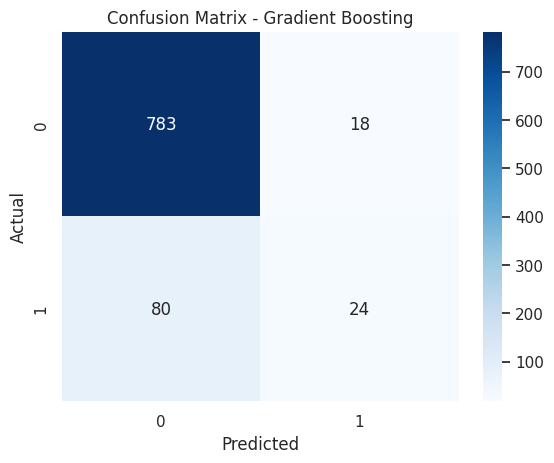

In [ ]:
best_name = results_df.loc[results_df["F1"].idxmax(), "Model"]
best_model = models[best_name]

cm = confusion_matrix(
    y_test,
    best_model.predict(X_test),
    labels=["no", "yes"]
)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

10. Create one bar chart comparing the F1-score of all models.

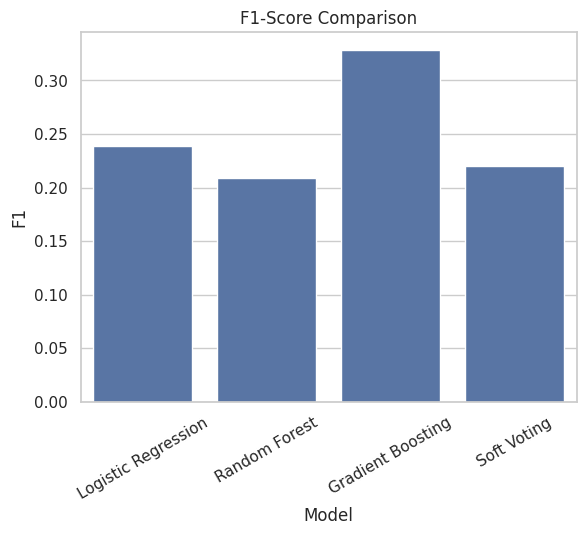

In [ ]:
sns.barplot(data=results_df, x="Model", y="F1")
plt.xticks(rotation=30)
plt.title("F1-Score Comparison")
plt.show()

11. Write two short paragraphs:

• Paragraph 1: Which model performed best and why?

Gradient Boosting performed best with an F1-score of 0.329. It achieved the highest F1-score among the four models, providing the best balance between precision and recall. This is important because the Bank Marketing dataset is imbalanced.

• Paragraph 2: What risks should be considered when using advanced ensembles on imbalanced data?

Advanced ensembles can overfit and require more computational resources. On imbalanced datasets, models may favor the majority class, making accuracy misleading. Therefore, precision, recall, F1-score, and ROC-AUC should also be considered.